<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_076_voting_stacking_ensembles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 76/365 — Voting & Stacking Ensembles
## Can multiple models together outperform a single model?

Today we cover a popular ensemble-learning idea:

**Voting and Stacking**

Instead of trusting one model, we combine predictions from several models.

If the models make different kinds of mistakes, the combined prediction can be stronger.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.metrics import accuracy_score


## 1. Load a real dataset


In [2]:
data=load_breast_cancer(as_frame=True)

X=data.data
y=data.target

X_train,X_test,y_train,y_test=train_test_split(
    X,y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Dataset shape:",X.shape)


Dataset shape: (569, 30)


## 2. Create three different models

We combine:
- Logistic Regression
- KNN
- Random Forest

These models learn differently, which is useful for ensembles.


In [3]:
log_reg=Pipeline([
    ("scaler",StandardScaler()),
    ("model",LogisticRegression(max_iter=3000))
])

knn=Pipeline([
    ("scaler",StandardScaler()),
    ("model",KNeighborsClassifier(n_neighbors=5))
])

rf=RandomForestClassifier(
    n_estimators=300,
    random_state=42
)


## 3. Train each model separately


In [4]:
models={
    "Logistic Regression":log_reg,
    "KNN":knn,
    "Random Forest":rf
}

results=[]

for name,model in models.items():
    model.fit(X_train,y_train)
    pred=model.predict(X_test)

    results.append({
        "Model":name,
        "Accuracy":accuracy_score(y_test,pred)
    })

baseline_df=pd.DataFrame(results)
display(baseline_df.round(3))


,Model,Accuracy
0,Logistic Regression,0.986
1,KNN,0.979
2,Random Forest,0.958


## 4. Hard Voting

Each model votes for a class.

Example:

- Model A → Positive
- Model B → Positive
- Model C → Negative

Final prediction:

**Positive**


In [5]:
hard_voting=VotingClassifier(
    estimators=[
        ("lr",log_reg),
        ("knn",knn),
        ("rf",rf)
    ],
    voting="hard"
)

hard_voting.fit(X_train,y_train)
hard_pred=hard_voting.predict(X_test)

print(
    "Hard Voting Accuracy:",
    round(accuracy_score(y_test,hard_pred),3)
)


Hard Voting Accuracy: 0.986


## 5. Soft Voting

Soft voting combines predicted probabilities.

Example:

- Model A → 0.80
- Model B → 0.55
- Model C → 0.40

Average:

`(0.80 + 0.55 + 0.40) / 3 = 0.583`

So the final class is positive at a 0.5 threshold.


In [6]:
soft_voting=VotingClassifier(
    estimators=[
        ("lr",log_reg),
        ("knn",knn),
        ("rf",rf)
    ],
    voting="soft"
)

soft_voting.fit(X_train,y_train)
soft_pred=soft_voting.predict(X_test)

print(
    "Soft Voting Accuracy:",
    round(accuracy_score(y_test,soft_pred),3)
)


Soft Voting Accuracy: 0.986


## 6. Stacking

Stacking goes further.

The base models make predictions first.

Those predictions become features for another model called the:

**Meta-model**

The meta-model learns when to trust each base model.


In [7]:
stacking=StackingClassifier(
    estimators=[
        ("lr",log_reg),
        ("knn",knn),
        ("rf",rf)
    ],
    final_estimator=LogisticRegression(max_iter=3000),
    cv=5
)

stacking.fit(X_train,y_train)
stack_pred=stacking.predict(X_test)

print(
    "Stacking Accuracy:",
    round(accuracy_score(y_test,stack_pred),3)
)


Stacking Accuracy: 0.979


## 7. Compare all models


In [8]:
comparison=pd.concat([
    baseline_df,
    pd.DataFrame([
        {
            "Model":"Hard Voting",
            "Accuracy":accuracy_score(y_test,hard_pred)
        },
        {
            "Model":"Soft Voting",
            "Accuracy":accuracy_score(y_test,soft_pred)
        },
        {
            "Model":"Stacking",
            "Accuracy":accuracy_score(y_test,stack_pred)
        }
    ])
],ignore_index=True)

display(
    comparison
    .sort_values("Accuracy",ascending=False)
    .round(3)
)


,Model,Accuracy
0,Logistic Regression,0.986
3,Hard Voting,0.986
4,Soft Voting,0.986
1,KNN,0.979
5,Stacking,0.979
2,Random Forest,0.958


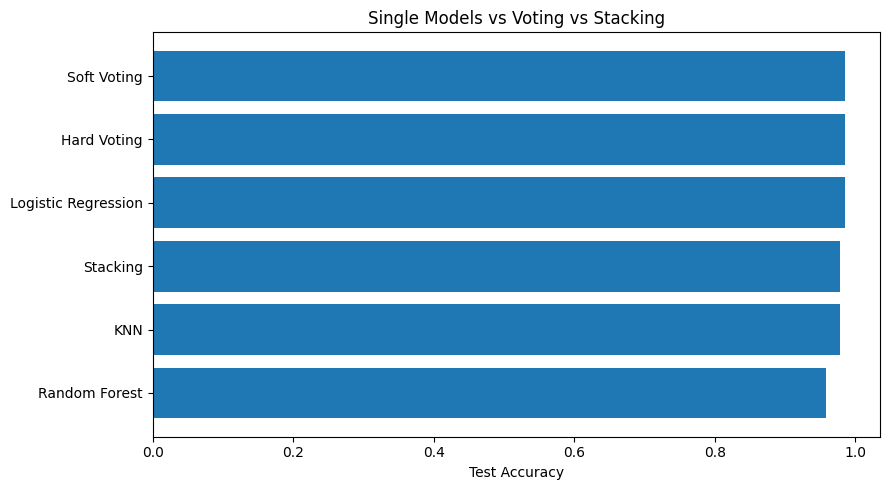

In [9]:
plot_df=comparison.sort_values("Accuracy")

plt.figure(figsize=(9,5))
plt.barh(
    plot_df["Model"],
    plot_df["Accuracy"]
)
plt.xlabel("Test Accuracy")
plt.title("Single Models vs Voting vs Stacking")
plt.tight_layout()
plt.show()


## 8. Voting vs Stacking

### Voting
Combines model outputs directly.

### Stacking
Learns how to combine model outputs using a meta-model.

Stacking is more flexible but also more complex.


## 9. Enterprise intuition

Imagine a fraud system with:

- Logistic Regression for simple global relationships
- Random Forest for nonlinear feature interactions
- KNN for similarity to historical cases

Because these models think differently, their errors may also differ.

Combining them can sometimes produce a stronger final prediction.

The same idea applies to:
- credit risk
- churn
- claims classification
- document classification
- demand prediction


## 10. Important leakage warning

Stacking must train the meta-model using **out-of-fold predictions**.

If the base models predict rows they were already trained on, the meta-model can overfit badly.

`StackingClassifier` handles this using cross-validation internally.


## What does this teach?

- Ensembles combine multiple models.
- Hard voting combines class labels.
- Soft voting combines probabilities.
- Stacking uses a meta-model.
- Model diversity matters.
- Stacking must avoid leakage.
- Ensembles still need proper validation.

> **Instead of asking which single model is best, ensemble learning asks whether several different models can make a better decision together.**


## References

- https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html
- https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html
- https://scikit-learn.org/stable/modules/ensemble.html
- https://doi.org/10.1016/S0893-6080(05)80023-1
